# TDGSA in ANSI C and CUDA: Build, Verify, Benchmark

**Colin Casey, 2026.** Companion to `TDGSA_Dispersion_Phase_Recovery.ipynb`, based on the ECE 279AS project [1].

Three implementations of the same algorithm on the same problem: the gas cell from Section 4 of the main notebook (1550 nm, $T_0 = 0.3$ ps, $D_1 = 0$, $D_2 = 10$ ps/nm, flat initial phase, $N = 2^{15}$).

| File | Language | FFT |
|---|---|---|
| `c/tdgsa.c` | ANSI C89 (`gcc -std=c89 -pedantic`) | hand-written iterative radix-2 Cooley-Tukey [2] |
| `c/tdgsa.cu` | CUDA C++ (`nvcc -arch=sm_89`) | cuFFT, double precision [3] |
| this notebook | Python / NumPy | `numpy.fft` (pocketfft) |

Both compiled programs take `<iterations> <output_prefix>` and write raw little-endian `float64` binaries (`_F.bin` complex spectrum, `_err.bin` error per iteration), which NumPy reads with `np.fromfile`.

In [1]:
import subprocess, time, pathlib
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

CDIR = pathlib.Path('c').resolve()   # notebook runs from projects/tdgsa_qis/
OUT = CDIR / 'out'; OUT.mkdir(exist_ok=True)

def run(cmd, **kw):
    r = subprocess.run(cmd, capture_output=True, text=True, **kw)
    return (r.stdout + r.stderr).strip()

print(run(['gcc', '--version']).splitlines()[0])
print(run(['nvcc', '--version']).splitlines()[-2])
print(run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader']))

gcc (Rev5, Built by MSYS2 project) 15.1.0
Cuda compilation tools, release 13.0, V13.0.48
NVIDIA GeForce RTX 4060, 8188 MiB


## 1. Build

`build.bat` compiles the C version with gcc under strict C89 (no `//` comments, no `complex.h`, declarations at block start), then loads the MSVC environment (`vcvars64.bat`, which nvcc needs on Windows) and compiles the CUDA version against cuFFT.

In [2]:
log = run(['cmd', '/c', str(CDIR / 'build.bat')], cwd=CDIR)
print('\n'.join(l for l in log.splitlines() if 'vswhere' not in l and 'operable program' not in l))
print('\nexecutables:', [f.name for f in CDIR.glob('*.exe')])

=== ANSI C (gcc -std=c89) ===
built tdgsa_c.exe
=== CUDA (nvcc + cuFFT) ===
tdgsa.cu
tmpxft_000117d0_00000000-7_tdgsa.cudafe1.cpp
built tdgsa_cuda.exe
Build OK.

executables: ['tdgsa_cuda.exe', 'tdgsa_c.exe']


## 2. The same problem in NumPy (reference)

In [3]:
c, lam = 299792458.0, 1550e-9
N, dt, T0 = 2**15, 0.06e-12, 0.3e-12
t = (np.arange(N) - N//2) * dt
w = 2*np.pi*np.fft.fftfreq(N, dt)
beta2L = lambda D: -D*1e-3*lam**2/(2*np.pi*c)
Dop = lambda D: np.exp(-1j*beta2L(D)*w**2/2)
LINES = [(-400e9, 3e9, 1.5), (-80e9, 1e9, 2.0), (60e9, 1e9, 2.5), (300e9, 4e9, 1.2), (900e9, 6e9, 0.8)]
H = np.ones(N, complex)
for f0, g, a in LINES:
    H *= np.exp(-a / (1 - 1j*(w - 2*np.pi*f0)/(2*np.pi*g)))
F_true = np.fft.fft(np.exp(-t**2/(2*T0**2))) * H
A1 = np.abs(np.fft.ifft(F_true*Dop(0.0))); A2 = np.abs(np.fft.ifft(F_true*Dop(10.0)))
H12 = Dop(10.0)/Dop(0.0); H21 = 1/H12

def tdgsa_numpy(n_iter):
    f1 = A1.astype(complex); err = np.empty(n_iter)
    for i in range(n_iter):
        f2 = np.fft.ifft(np.fft.fft(f1)*H12)
        err[i] = np.linalg.norm(np.abs(f2) - A2)/np.linalg.norm(A2)
        f2 = A2*np.exp(1j*np.angle(f2))
        f1 = np.fft.ifft(np.fft.fft(f2)*H21); f1 = A1*np.exp(1j*np.angle(f1))
    return np.fft.fft(f1)/Dop(0.0), err

def field_error(F):
    m = np.abs(F_true) > 1e-3*np.abs(F_true).max()
    gph = np.vdot(F[m], F_true[m]); gph /= abs(gph)
    return np.linalg.norm(F[m]*gph - F_true[m])/np.linalg.norm(F_true[m])

## 3. Correctness: all three agree

In [4]:
def run_binary(exe, n_iter):
    tag = f'{exe.stem}_{n_iter}'
    line = run([str(exe), str(n_iter), str(OUT / tag)])
    ms = float(line.split('time_ms=')[1].split()[0])
    F = np.fromfile(OUT / f'{tag}_F.bin', dtype=np.complex128)
    e = np.fromfile(OUT / f'{tag}_err.bin', dtype=np.float64)
    return F, e, ms, line

Fp, ep = tdgsa_numpy(100)
print(f'{"backend":10s} {"max|F-F_numpy|/max|F|":>24s} {"max err-curve diff":>20s} {"field error":>12s}')
print(f'{"NumPy":10s} {0:24.2e} {0:20.2e} {field_error(Fp):12.6f}')
for exe in (CDIR/'tdgsa_c.exe', CDIR/'tdgsa_cuda.exe'):
    F, e, ms, line = run_binary(exe, 100)
    print(f'{exe.stem:10s} {np.abs(F-Fp).max()/np.abs(Fp).max():24.2e} {np.abs(e-ep).max():20.2e} {field_error(F):12.6f}')

backend       max|F-F_numpy|/max|F|   max err-curve diff  field error
NumPy                      0.00e+00             0.00e+00     0.024045


tdgsa_c                    5.43e-07             3.12e-09     0.024045


tdgsa_cuda                 2.93e-08             1.66e-10     0.024045


Differences of $10^{-7}$ to $10^{-8}$ are floating-point rounding from different FFT algorithms (radix-2 vs pocketfft vs cuFFT), accumulated over 400 FFTs. All three land on the same field error.

## 4. Benchmark: 1, 10, 100, 1000, 10⁴ iterations

Timing covers only the iteration loop (C: `clock()`, CUDA: `cudaEvent`, NumPy: `perf_counter`). NumPy at 10⁴ iterations takes about a minute.

In [5]:
iters = [1, 10, 100, 1000, 10_000]
times = {'ANSI C': [], 'CUDA': [], 'NumPy': []}
final_err = {}
for n in iters:
    _, e, ms, _ = run_binary(CDIR/'tdgsa_c.exe', n); times['ANSI C'].append(ms)
    F, e, ms, _ = run_binary(CDIR/'tdgsa_cuda.exe', n); times['CUDA'].append(ms); final_err[n] = (e[-1], field_error(F))
    t0 = time.perf_counter(); tdgsa_numpy(n); times['NumPy'].append(1e3*(time.perf_counter() - t0))

print(f'{"iterations":>10s} {"ANSI C (ms)":>12s} {"NumPy (ms)":>11s} {"CUDA (ms)":>10s} {"GPU vs C":>9s} {"meas err":>10s} {"field err":>10s}')
for i, n in enumerate(iters):
    print(f'{n:10d} {times["ANSI C"][i]:12.1f} {times["NumPy"][i]:11.1f} {times["CUDA"][i]:10.2f} '
          f'{times["ANSI C"][i]/times["CUDA"][i]:8.1f}x {final_err[n][0]:10.2e} {final_err[n][1]:10.4f}')

iterations  ANSI C (ms)  NumPy (ms)  CUDA (ms)  GPU vs C   meas err  field err
         1          8.0         5.9       1.40      5.7x   1.64e-01     0.1490
        10         71.0        41.9       6.62     10.7x   8.33e-03     0.0296
       100        651.0       483.3      45.78     14.2x   4.69e-03     0.0240
      1000       7603.0      5567.5     501.67     15.2x   4.06e-03     0.0234
     10000      79783.0     46000.0    3688.52     21.6x   3.68e-03     0.0220


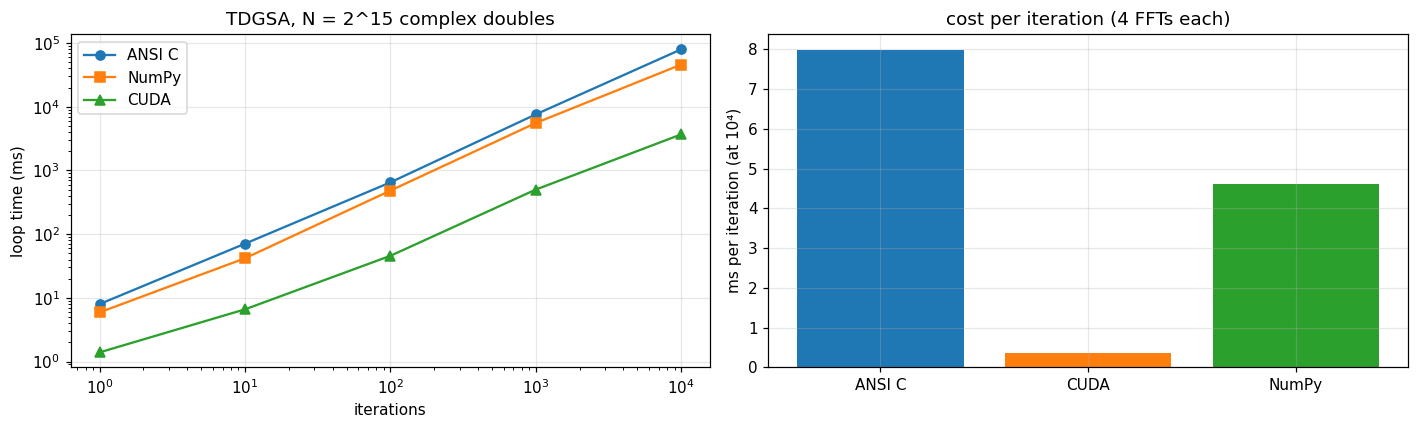

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, mk in (('ANSI C', 'o-'), ('NumPy', 's-'), ('CUDA', '^-')):
    ax[0].loglog(iters, times[name], mk, label=name)
ax[0].set_xlabel('iterations'); ax[0].set_ylabel('loop time (ms)'); ax[0].legend(); ax[0].set_title(f'TDGSA, N = 2^15 complex doubles')
per_it = {k: np.array(v)/np.array(iters) for k, v in times.items()}
ax[1].bar(list(per_it), [v[-1] for v in per_it.values()], color=['C0', 'C1', 'C2'])
ax[1].set_ylabel('ms per iteration (at 10⁴)'); ax[1].set_title('cost per iteration (4 FFTs each)')
plt.tight_layout(); plt.show()

## 5. Notes

- **Where CUDA time goes:** each iteration copies one `double` (the error sum) back to the host, which forces a GPU sync. Dropping the per-iteration error, or computing it every 10th iteration, would make the GPU loop noticeably faster.
- **N = 2¹⁵ is small for a GPU.** The speedup grows with $N$, and with batching many shots (Section 7 of the main notebook) as a `cufftPlanMany` batch.
- **ANSI C portability:** `tdgsa.c` uses only C89 + `libm`, so it compiles with gcc, clang, MSVC, or an embedded toolchain without changes.

## References

[1] G. Morozowsky and C. Casey, "Dispersion assisted optical phase recovery," presented at ECE 279AS, Univ. of California, Los Angeles, CA, USA, Mar. 13, 2024 (unpublished course presentation).

[2] J. W. Cooley and J. W. Tukey, "An algorithm for the machine calculation of complex Fourier series," *Math. Comput.*, vol. 19, no. 90, pp. 297–301, 1965, doi: 10.1090/S0025-5718-1965-0178586-1.

[3] NVIDIA Corporation, "cuFFT library user's guide," CUDA Toolkit Documentation, 2025. [Online]. Available: https://docs.nvidia.com/cuda/cufft/

[4] R. W. Gerchberg and W. O. Saxton, "A practical algorithm for the determination of phase from image and diffraction plane pictures," *Optik*, vol. 35, no. 2, pp. 237–246, 1972.